# Random Forest com características linguísticas (handcrafted features)

O objetivo de testar essa estratégia é tentar extrair características explícitas dos textos, como:

- Comprimento médio das sentenças e palavras.
- Diversidade vocabular.
- Frequência de palavras incomuns.
- Complexidade sintática.
- Frequência de conectivos e pontuação.

A Random Forest pode identificar interações não lineares entre essas características. Além disso, permite analisar quais propriedades linguísticas são mais relevantes para a classificação.

## Carregando dataset de treino e teste

## Importando bibliotecas

In [4]:
import pandas as pd
import numpy as np

# Para os próximos passos (ainda não usadas):
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import accuracy_score, classification_report

## Carregando dataset de treino e teste

- `train_limpo.csv`: treino (com rótulo `clarity`).
- `test1_limpo.csv`: teste do EP1 (agora com rótulo). Será usado **apenas** na avaliação final e no teste de McNemar (EP1 x EP2).
- `test2_limpo.csv`: teste oficial do EP2 (sem rótulo). Será usado **apenas** para gerar as predições finais.

> Atenção: segundo o enunciado, não se pode comparar modelos usando o teste2. Escolhas de modelo/hiperparâmetros devem ser feitas só com validação cruzada ou um split do treino.

In [5]:
train = pd.read_csv("data/train_limpo.csv")
test1 = pd.read_csv("data/test1_limpo.csv")
test2 = pd.read_csv("data/test2_limpo.csv")

print("train:", train.shape)
print("test1:", test1.shape)
print("test2:", test2.shape)

train: (20092, 2)
test1: (900, 2)
test2: (897, 2)


### Conferindo os dados

In [6]:
# Colunas e valores faltantes
for nome, df in [("train", train), ("test1", test1), ("test2", test2)]:
    print(nome, list(df.columns), "| nulos em resp_text:", df["resp_text"].isna().sum())

# Distribuição das classes
print("\nTreino:\n", train["clarity"].value_counts(normalize=True).round(3))
print("\nTeste1:\n", test1["clarity"].value_counts(normalize=True).round(3))
print("\nTeste2 (deve estar sem rótulo):", test2["clarity"].notna().sum(), "rótulos")

train ['resp_text', 'clarity'] | nulos em resp_text: 0
test1 ['resp_text', 'clarity'] | nulos em resp_text: 0
test2 ['resp_text', 'clarity'] | nulos em resp_text: 0

Treino:
 clarity
c5      0.343
c234    0.341
c1      0.316
Name: proportion, dtype: float64

Teste1:
 clarity
c5      0.333
c1      0.333
c234    0.333
Name: proportion, dtype: float64

Teste2 (deve estar sem rótulo): 0 rótulos


In [7]:
train.head()

,resp_text,clarity
0,prezado a senhor a esclarecemos que o serviço ...,c5
1,prezada cidadã as informações sobre óbitos no ...,c1
2,prezado senhor julio a ouvidoria geral da petr...,c1
3,prezado a senhor a esclarecemos que o serviço ...,c234
4,senhor o serviço de informações ao cidadão do ...,c234


## Decisão: limpeza específica para as características linguísticas

A limpeza (`Limpeza.ipynb`) converte tudo para minúsculas e **troca toda a pontuação por espaço**. Isso é adequado para TF-IDF, mas apaga justamente informações que queremos medir aqui: fim de frases (comprimento médio de sentenças), vírgulas, pontos de interrogação/exclamação e uso de maiúsculas.

Por isso:

- **Não alteramos** o código de limpeza geral, para manter os resultados anteriores reprodutíveis (importante para o teste de McNemar EP1 x EP2).
- Criamos uma **limpeza básica alternativa** para este modelo, que remove apenas ruído (URLs, e-mails, menções/hashtags e espaços repetidos) e **preserva pontuação e capitalização**.
- Aplicamos a mesma função ao treino, teste1 e teste2, partindo dos arquivos originais.
- Características que não dependem de pontuação (ex.: tamanho de palavras, diversidade lexical) continuam podendo ser calculadas sobre o texto sem pontuação.

Os CSVs `*_limpo.csv` carregados acima continuam disponíveis para comparação.

In [8]:
import re

def limpar_texto_para_features(texto):
    """Limpeza básica que preserva pontuação e maiúsculas/minúsculas."""
    if not isinstance(texto, str):
        return ""
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)   # URLs
    texto = re.sub(r'\S+@\S+\.\S+', ' ', texto)       # e-mails
    texto = re.sub(r'[@#]\w+', ' ', texto)             # menções e hashtags
    texto = re.sub(r'\s+', ' ', texto).strip()         # espaços e quebras de linha
    return texto

### Aplicando a limpeza aos dados originais

In [9]:
train_raw = pd.read_csv("data/train.csv")
test1_raw = pd.read_excel("data/test1-rotulado-para-teste-estatistico.xlsx")
test2_raw = pd.read_excel("data/test2.xlsx")

def preparar(df):
    df = df.copy()
    df["resp_text"] = df["resp_text"].apply(limpar_texto_para_features)
    return df[[c for c in ["resp_text", "clarity"] if c in df.columns]]

train_f = preparar(train_raw)
test1_f = preparar(test1_raw)
test2_f = preparar(test2_raw)

print("train:", train_f.shape, "| test1:", test1_f.shape, "| test2:", test2_f.shape)
# Os tamanhos devem bater com os datasets limpos do EP1
assert len(train_f) == len(train) and len(test1_f) == len(test1) and len(test2_f) == len(test2)
train_f["resp_text"].iloc[0][:300]

train: (20092, 2) | test1: (900, 2) | test2: (897, 2)


'Prezado(a) Senhor(a), Esclarecemos que o Serviço de Informação ao Cidadão (SIC) não trata de sugestão, elogio, solicitação, reclamação e denúncia relacionados a objetos postados no Brasil ou no exterior. Cumpre-nos esclarecer que a Comissão Mista de Reavaliação de Informações (CMRI), por meio da Súm'

## Extração das características linguísticas

Cada resposta é transformada em um vetor de características numéricas, agrupadas em:

| Grupo | Características |
|---|---|
| Tamanho | nº de caracteres, palavras e sentenças |
| Sentenças | média e máximo de palavras por sentença |
| Palavras / legibilidade | tamanho médio da palavra, proporção de palavras longas (≥10 letras), sílabas por palavra, proporção de polissílabas, **índice de Flesch adaptado ao português** (Martins et al., 1996) |
| Diversidade vocabular | TTR (tipos/tokens), TTR raiz (tipos/√tokens, menos sensível ao tamanho do texto), proporção de hapax (palavras que aparecem uma só vez) |
| Palavras incomuns | proporção de palavras que aparecem menos de 5 vezes no **corpus de treino** |
| Conectivos e negação | proporção de conectivos (adição, oposição, causa, conclusão…) e de negações |
| Pontuação | vírgulas por sentença, proporção de pontuação, nº de `?`, `!`, `(` e `:` |
| Outros | proporção de maiúsculas e de dígitos |

Observações:
- Sentenças são separadas por `.`, `!`, `?` e `;`, e sílabas são aproximadas pelo número de grupos de vogais. São heurísticas simples, sem parser sintático.
- O dicionário de frequências usado em "palavras incomuns" é construído **apenas com o treino** e reaplicado ao teste1 e ao teste2, para não vazar informação dos testes.

In [10]:
from collections import Counter

# ---------------------------------------------------------------- recursos
CONECTIVOS = {
    # adição / sequência
    "e", "também", "além", "ainda", "ademais", "outrossim",
    # oposição
    "mas", "porém", "contudo", "entretanto", "todavia", "embora", "enquanto",
    # causa / explicação
    "porque", "pois", "porquanto", "visto", "como",
    # conclusão
    "portanto", "logo", "assim", "consequentemente", "dessa", "desse", "deste", "desta",
    # condição
    "se", "caso", "desde",
    # finalidade
    "para", "afim",
    # reformulação
    "ou", "seja", "isto",
}
NEGACOES = {"não", "nem", "nunca", "jamais", "nenhum", "nenhuma", "nada", "ninguém"}

RE_PALAVRA = re.compile(r"[^\W\d_]+", re.UNICODE)       # só letras
RE_SENTENCA = re.compile(r"[.!?;]+(?:\s+|$)")
RE_VOGAIS = re.compile(r"[aeiouáéíóúâêôãõàü]+")


def contar_silabas(palavra):
    """Aproximação: número de grupos de vogais."""
    return max(1, len(RE_VOGAIS.findall(palavra.lower())))


def construir_frequencias(textos):
    """Frequência das palavras no corpus de treino (para medir palavras incomuns)."""
    contagem = Counter()
    for t in textos:
        contagem.update(p.lower() for p in RE_PALAVRA.findall(t))
    return contagem


def extrair_features(texto, freq_treino, limiar_rara=5):
    palavras = RE_PALAVRA.findall(texto)
    palavras_min = [p.lower() for p in palavras]
    sentencas = [s for s in RE_SENTENCA.split(texto) if RE_PALAVRA.search(s)]

    n_chars = len(texto)
    n_palavras = len(palavras)
    n_sent = max(1, len(sentencas))
    n = max(1, n_palavras)  # evita divisão por zero

    palavras_por_sent = [len(RE_PALAVRA.findall(s)) for s in sentencas] or [0]
    silabas = [contar_silabas(p) for p in palavras_min]
    n_silabas = sum(silabas)
    tipos = set(palavras_min)
    contagem = Counter(palavras_min)

    # Índice de Flesch adaptado ao português (Martins et al., 1996)
    flesch = 248.835 - 1.015 * (n_palavras / n_sent) - 84.6 * (n_silabas / n)

    return {
        # tamanho
        "n_caracteres": n_chars,
        "n_palavras": n_palavras,
        "n_sentencas": len(sentencas),
        # sentenças
        "media_palavras_sentenca": np.mean(palavras_por_sent),
        "max_palavras_sentenca": np.max(palavras_por_sent),
        # palavras
        "media_tam_palavra": np.mean([len(p) for p in palavras]) if palavras else 0,
        "prop_palavras_longas": sum(len(p) >= 10 for p in palavras) / n,
        "media_silabas_palavra": n_silabas / n,
        "prop_polissilabas": sum(s >= 4 for s in silabas) / n,
        "flesch_pt": flesch,
        # diversidade vocabular
        "ttr": len(tipos) / n,
        "ttr_raiz": len(tipos) / np.sqrt(n),           # menos sensível ao tamanho
        "prop_hapax": sum(c == 1 for c in contagem.values()) / n,
        # palavras incomuns (frequência no treino)
        "prop_palavras_raras": sum(freq_treino.get(p, 0) < limiar_rara for p in palavras_min) / n,
        # conectivos e negação
        "prop_conectivos": sum(p in CONECTIVOS for p in palavras_min) / n,
        "prop_negacoes": sum(p in NEGACOES for p in palavras_min) / n,
        # pontuação
        "virgulas_por_sentenca": texto.count(",") / n_sent,
        "prop_pontuacao": sum(not c.isalnum() and not c.isspace() for c in texto) / max(1, n_chars),
        "n_interrogacoes": texto.count("?"),
        "n_exclamacoes": texto.count("!"),
        "n_parenteses": texto.count("("),
        "n_dois_pontos": texto.count(":"),
        # outros
        "prop_maiusculas": sum(c.isupper() for c in texto) / max(1, n_chars),
        "prop_digitos": sum(c.isdigit() for c in texto) / max(1, n_chars),
    }


def gerar_matriz(textos, freq_treino):
    return pd.DataFrame([extrair_features(t, freq_treino) for t in textos])


### Gerando as matrizes de características

In [11]:
freq_treino = construir_frequencias(train_f["resp_text"])  # só o treino!

X_train = gerar_matriz(train_f["resp_text"], freq_treino)
X_test1 = gerar_matriz(test1_f["resp_text"], freq_treino)
X_test2 = gerar_matriz(test2_f["resp_text"], freq_treino)

y_train = train_f["clarity"]
y_test1 = test1_f["clarity"]

print("X_train:", X_train.shape, "| X_test1:", X_test1.shape, "| X_test2:", X_test2.shape)
print("Valores faltantes:", X_train.isna().sum().sum())
X_train.describe().T.round(2)

X_train: (20092, 24) | X_test1: (900, 24) | X_test2: (897, 24)
Valores faltantes: 0


,count,mean,std,min,25%,50%,75%,max
n_caracteres,20092.0,944.80,974.79,5.00,315.00,665.00,1230.00,12113.00
n_palavras,20092.0,139.35,144.17,1.00,46.00,98.00,181.00,1789.00
n_sentencas,20092.0,5.79,5.06,1.00,3.00,4.00,7.00,80.00
media_palavras_sentenca,20092.0,23.07,13.54,1.00,15.00,22.00,28.71,616.00
max_palavras_sentenca,20092.0,46.20,31.81,1.00,25.00,41.00,59.00,650.00
media_tam_palavra,20092.0,5.39,0.45,1.00,5.14,5.36,5.60,10.50
prop_palavras_longas,20092.0,0.15,0.05,0.00,0.13,0.15,0.18,1.00
media_silabas_palavra,20092.0,2.29,0.18,1.00,2.19,2.27,2.37,4.50
prop_polissilabas,20092.0,0.20,0.06,0.00,0.17,0.20,0.23,1.00
flesch_pt,20092.0,31.65,19.98,-640.37,21.57,31.92,42.71,163.22


### Média das características por classe

Uma primeira olhada em quais características variam entre as classes. Diferenças pequenas aqui não excluem uma característica, porque a Random Forest pode aproveitar combinações não lineares entre elas.

In [12]:
X_train.assign(clarity=y_train).groupby("clarity").mean().T.round(3)

clarity,c1,c234,c5
n_caracteres,997.475,1027.674,813.881
n_palavras,147.347,151.640,119.766
n_sentencas,5.937,6.168,5.268
media_palavras_sentenca,23.554,23.696,21.993
max_palavras_sentenca,48.036,48.083,42.637
media_tam_palavra,5.374,5.393,5.413
prop_palavras_longas,0.155,0.155,0.155
media_silabas_palavra,2.282,2.288,2.300
prop_polissilabas,0.199,0.199,0.198
flesch_pt,31.831,31.191,31.941


## Experimento 1: Random Forest apenas com as 24 características linguísticas

> Resultado: **0,422** de acurácia na validação cruzada (cerca de 5 min de execução). Como referência, o modelo do EP1 (regressão logística + TF-IDF) teve **0,4632** na validação cruzada e 0,4967 no teste1.

Os hiperparâmetros são escolhidos com `GridSearchCV`, usando **validação cruzada estratificada com 5 folds** **só no treino**. Nem o teste1 nem o teste2 entram nessa etapa.

Hiperparâmetros avaliados:
- `max_depth`: profundidade máxima de cada árvore (`None` = sem limite). Árvores mais rasas reduzem o overfitting.
- `min_samples_leaf`: número mínimo de exemplos em cada folha. Valores maiores suavizam o modelo.
- `class_weight`: `None` ou `"balanced"`, que dá mais peso às classes menos frequentes.

Mantemos fixos `n_estimators=200` e `max_features="sqrt"`. Num teste preliminar com `max_features=0.5` e 300 árvores, o resultado foi praticamente o mesmo (diferença < 0.001), mas o tempo de execução foi muito maior.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 5, 10],
    "class_weight": [None, "balanced"],
}

rf = RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=123, n_jobs=-1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

grid_rf = GridSearchCV(
    rf,
    param_grid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    verbose=1,
)
grid_rf.fit(X_train, y_train)

print("Melhores parâmetros:", grid_rf.best_params_)
print(f"Acurácia média na validação cruzada: {grid_rf.best_score_:.4f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Melhores parâmetros: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_leaf': 10}
Acurácia média na validação cruzada: 0.4219


### Resultados de todas as combinações

Comparar a acurácia de treino com a de validação ajuda a ver se o modelo está decorando o treino (overfitting).

In [14]:
resultados = pd.DataFrame(grid_rf.cv_results_)
colunas = ["param_max_depth", "param_min_samples_leaf", "param_class_weight",
           "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]
resultados[colunas].sort_values("rank_test_score").round(4)

,param_max_depth,param_min_samples_leaf,param_class_weight,mean_train_score,mean_test_score,std_test_score,rank_test_score
17,20,10,balanced,0.8256,0.4219,0.0048,1
13,10,5,balanced,0.6444,0.4207,0.0069,2
11,None,10,balanced,0.8384,0.4204,0.0049,3
2,None,10,NaN,0.8285,0.4193,0.0055,4
1,None,5,NaN,0.9228,0.4184,0.0077,5
14,10,10,balanced,0.6082,0.4180,0.0049,6
8,20,10,NaN,0.8130,0.4180,0.0044,7
3,10,1,NaN,0.6773,0.4179,0.0061,8
10,None,5,balanced,0.9236,0.4179,0.0080,9
4,10,5,NaN,0.6308,0.4179,0.0049,10


## Experimento 2: características lexicais + léxico de clareza

O Experimento 1 mostrou que características só de estilo e legibilidade (tamanho, pontuação, diversidade) não bastam: todas as combinações do grid ficaram entre 0,418 e 0,423. Ampliar o grid não resolve, então o caminho é dar ao modelo **características mais informativas**, ainda linguísticas e interpretáveis.

Acrescentamos dois tipos de características:

1. **Grupos lexicais (15 características)**: proporção de palavras/expressões ligadas a funções discursivas típicas das respostas do e-SIC, como menção a anexos, encaminhamento a outro órgão, inexistência da informação, sigilo/legislação, fórmulas de cortesia, além de traços gramaticais (voz passiva, gerúndio, verbos modais, 1ª pessoa do plural). São listas fixas definidas por nós, sem aprendizado.
2. **Léxico de clareza aprendido do corpus (9 características)**: para cada classe, calculamos o *log-odds* suavizado de cada palavra, que mede o quanto a palavra é mais comum em respostas daquela classe do que nas demais. Cada texto é resumido pela **média, máximo e mínimo** desses valores para cada classe (3 × 3 = 9 números).

Em testes preliminares (5 folds, hiperparâmetros fixos), os grupos lexicais levaram a acurácia de 0,422 para 0,437 e o léxico de clareza para 0,447.

### Grupos lexicais

In [15]:
GRUPOS_LEXICAIS = {
    # menção a anexos e a fontes externas de informação
    "anexo": r"\banex",
    "link": r"\blink|\bsítio|\bsite|\bportal|endereço eletrônico",
    # encaminhamento / falta de competência do órgão
    "encaminhamento": r"encaminh|redirecion|outro órgão|competência|não compete|não é competente",
    # inexistência da informação
    "inexistencia": r"não (?:possui|dispõe|há|existe|detém)|inexist",
    # sigilo, restrição de acesso e legislação
    "sigilo_legislacao": r"sigil|restri|classificad|pessoal|lgpd|lei 12\.?527|art\.",
    # fórmulas de resposta direta
    "resposta_direta": r"informamos|esclarecemos|segue|seguem|conforme",
    # recurso e prazos
    "recurso_prazo": r"recurso|prazo|dias",
    # fórmulas de cortesia
    "cortesia": r"agradec|atenciosamente|cordialmente|à disposição",
    # referência ao próprio pedido
    "referencia_pedido": r"pedido|solicitação|demanda|manifestação",
    # dados concretos
    "valores_numericos": r"r\$|\d+[.,]\d+",
    "datas": r"\d{1,2}/\d{1,2}/\d{2,4}",
    # traços gramaticais
    "primeira_pessoa_plural": r"\b(?:nós|nosso|nossa|informamos|esclarecemos|encaminhamos)\b",
    "voz_passiva": r"\b(?:foi|foram|é|são|será|serão)\s+\w+(?:ado|ada|ados|adas|ido|ida|idos|idas)\b",
    "gerundio": r"\w+ndo\b",
    "modais": r"\b(?:pode|podem|poderá|deve|devem|deverá|necessário)\b",
}


def features_lexicais(textos, n_palavras):
    """Proporção (por palavra) de ocorrências de cada grupo lexical."""
    textos_min = pd.Series(textos).str.lower().reset_index(drop=True)
    n = pd.Series(n_palavras).clip(lower=1).reset_index(drop=True)
    return pd.DataFrame({f"lex_{nome}": textos_min.str.count(regex) / n
                         for nome, regex in GRUPOS_LEXICAIS.items()})


In [16]:
L_train = features_lexicais(train_f["resp_text"], X_train["n_palavras"])
L_test1 = features_lexicais(test1_f["resp_text"], X_test1["n_palavras"])
L_test2 = features_lexicais(test2_f["resp_text"], X_test2["n_palavras"])

L_train.assign(clarity=y_train.values).groupby("clarity").mean().T.round(4)


clarity,c1,c234,c5
lex_anexo,0.0067,0.0077,0.0105
lex_link,0.0042,0.0040,0.0035
lex_encaminhamento,0.0044,0.0044,0.0047
lex_inexistencia,0.0013,0.0015,0.0021
lex_sigilo_legislacao,0.0057,0.0046,0.0041
lex_resposta_direta,0.0136,0.0141,0.0164
lex_recurso_prazo,0.0108,0.0099,0.0105
lex_cortesia,0.0125,0.0125,0.0156
lex_referencia_pedido,0.0158,0.0126,0.0128
lex_valores_numericos,0.0079,0.0069,0.0069


### Léxico de clareza

> **Cuidado com vazamento de dados:** como o léxico usa os rótulos, ele **não pode** ser calculado sobre o treino inteiro antes da validação cruzada. Senão, as palavras dos textos de validação já teriam "visto" seus rótulos. Por isso ele foi implementado como um *transformer* do scikit-learn e colocado dentro de um `Pipeline`: em cada fold, o léxico é aprendido só com os dados de treino daquele fold.

O parâmetro `min_freq` define em quantos documentos a palavra precisa aparecer para entrar no léxico, e `alpha` é a suavização, que evita valores extremos para palavras raras. Os dois entram no grid search.

In [17]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer


def _reduz_linhas(M, func):
    """Aplica max/min apenas sobre os valores presentes em cada linha de uma matriz esparsa."""
    M = M.tocsr()
    out = np.zeros(M.shape[0])
    linhas_nao_vazias = np.diff(M.indptr) > 0
    if linhas_nao_vazias.any():
        inicios = M.indptr[:-1][linhas_nao_vazias]
        out[linhas_nao_vazias] = func.reduceat(M.data, inicios)
    return out


class LexicoClareza(BaseEstimator, TransformerMixin):
    """Léxico de clareza aprendido do treino.

    No fit, calcula para cada classe o log-odds suavizado de cada palavra
    (quão mais frequente a palavra é nos documentos daquela classe do que nos demais).
    No transform, cada texto vira 9 números: média, máximo e mínimo do log-odds
    das suas palavras para cada uma das 3 classes. As demais colunas (características
    linguísticas) são repassadas sem alteração.
    """

    def __init__(self, col_texto="__texto", min_freq=5, alpha=1.0):
        self.col_texto = col_texto
        self.min_freq = min_freq
        self.alpha = alpha

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.vectorizer_ = CountVectorizer(token_pattern=r"[^\W\d_]+", lowercase=True,
                                           min_df=self.min_freq)
        D = self.vectorizer_.fit_transform(X[self.col_texto])
        D_bin = (D > 0).astype(np.float64)              # frequência de documento
        total = np.asarray(D_bin.sum(axis=0)).ravel()
        N = len(y)
        self.log_odds_ = []
        for c in self.classes_:
            mask = y == c
            n_c = mask.sum()
            a = np.asarray(D_bin[mask].sum(axis=0)).ravel() + self.alpha   # docs da classe c com a palavra
            b = total - a + 2 * self.alpha                                  # docs das outras classes com a palavra
            lo = (np.log(a / (n_c + 2 * self.alpha - a))
                  - np.log(b / (N - n_c + 2 * self.alpha - b)))
            self.log_odds_.append(lo)
        self.colunas_ = [col for col in X.columns if col != self.col_texto]
        return self

    def transform(self, X):
        D = self.vectorizer_.transform(X[self.col_texto]).tocsr().astype(np.float64)
        n_conhecidas = np.asarray(D.sum(axis=1)).ravel()
        blocos = [X[self.colunas_].to_numpy(dtype=np.float64)]
        for lo in self.log_odds_:
            M = D.multiply(lo).tocsr()                  # log-odds ponderado pela contagem
            media = np.asarray(M.sum(axis=1)).ravel() / np.maximum(n_conhecidas, 1)
            P = (D > 0).multiply(lo).tocsr()            # log-odds das palavras presentes
            blocos.append(np.column_stack([media, _reduz_linhas(P, np.maximum),
                                           _reduz_linhas(P, np.minimum)]))
        return np.hstack(blocos)

    def get_feature_names_out(self, input_features=None):
        nomes = list(self.colunas_)
        for c in self.classes_:
            nomes += [f"lexico_{c}_media", f"lexico_{c}_max", f"lexico_{c}_min"]
        return np.array(nomes)


### Montando a entrada do modelo

A entrada junta as 24 características linguísticas, os 15 grupos lexicais e uma coluna com o texto (`__texto`), que o `LexicoClareza` usa e depois descarta.

In [18]:
def montar_entrada(X_ling, X_lex, df_texto):
    entrada = pd.concat([X_ling.reset_index(drop=True), X_lex.reset_index(drop=True)], axis=1)
    entrada["__texto"] = df_texto["resp_text"].str.lower().values
    return entrada

Xc_train = montar_entrada(X_train, L_train, train_f)
Xc_test1 = montar_entrada(X_test1, L_test1, test1_f)
Xc_test2 = montar_entrada(X_test2, L_test2, test2_f)

print("Entrada do modelo:", Xc_train.shape, "(características + coluna de texto)")


Entrada do modelo: (20092, 40) (características + coluna de texto)


### Grid search ampliado (5 folds)

> ⏳ **Execução demorada:** 192 combinações × 5 folds = 960 treinos, o que deve levar **algumas horas**. O progresso aparece na saída da célula (`verbose=2`). Ao final, os resultados são salvos em `resultados_grid_rf2.csv` e o melhor modelo em `modelo_rf2.joblib`, para não precisar rodar de novo.

Hiperparâmetros avaliados:
- **Léxico:** `min_freq` (3 ou 10 documentos) e `alpha` (0,5 ou 1,0).
- **Random Forest:**
  - `n_estimators`: número de árvores (300 ou 600);
  - `max_depth`: profundidade máxima;
  - `min_samples_leaf`: mínimo de exemplos por folha;
  - `max_features`: fração das características sorteadas em cada divisão. Com quase 50 características, testamos `sqrt` (~7) e 30% (~14);
  - `class_weight`: `None` ou `"balanced"`.

O `memory=pasta_cache` do `Pipeline` guarda o léxico já calculado para cada fold, então ele não é recalculado a cada combinação de hiperparâmetros da Random Forest.

In [19]:
import tempfile, shutil, time
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pasta_cache = tempfile.mkdtemp()   # guarda o léxico já calculado para não refazê-lo a cada combinação

pipe = Pipeline(
    [
        ("lexico", LexicoClareza()),
        ("rf", RandomForestClassifier(random_state=123, n_jobs=-1)),
    ],
    memory=pasta_cache,
)

param_grid_2 = {
    # léxico de clareza
    "lexico__min_freq": [3, 10],
    "lexico__alpha": [0.5, 1.0],
    # random forest
    "rf__n_estimators": [300, 600],
    "rf__max_depth": [None, 20],
    "rf__min_samples_leaf": [2, 5, 10],
    "rf__max_features": ["sqrt", 0.3],
    "rf__class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
grid_rf2 = GridSearchCV(pipe, param_grid_2, cv=cv, scoring="accuracy", verbose=2)

inicio = time.time()
grid_rf2.fit(Xc_train, y_train)
shutil.rmtree(pasta_cache, ignore_errors=True)

print(f"Tempo total: {(time.time() - inicio) / 60:.1f} min")
print("Melhores parâmetros:", grid_rf2.best_params_)
print(f"Acurácia média na validação cruzada: {grid_rf2.best_score_:.4f}")


Fitting 5 folds for each of 192 candidates, totalling 960 fits
[CV] END lexico__alpha=0.5, lexico__min_freq=3, rf__class_weight=None, rf__max_depth=None, rf__max_features=sqrt, rf__min_samples_leaf=2, rf__n_estimators=300; total time=   7.2s
[CV] END lexico__alpha=0.5, lexico__min_freq=3, rf__class_weight=None, rf__max_depth=None, rf__max_features=sqrt, rf__min_samples_leaf=2, rf__n_estimators=300; total time=   5.3s
[CV] END lexico__alpha=0.5, lexico__min_freq=3, rf__class_weight=None, rf__max_depth=None, rf__max_features=sqrt, rf__min_samples_leaf=2, rf__n_estimators=300; total time=   5.2s
[CV] END lexico__alpha=0.5, lexico__min_freq=3, rf__class_weight=None, rf__max_depth=None, rf__max_features=sqrt, rf__min_samples_leaf=2, rf__n_estimators=300; total time=   8.1s
[CV] END lexico__alpha=0.5, lexico__min_freq=3, rf__class_weight=None, rf__max_depth=None, rf__max_features=sqrt, rf__min_samples_leaf=2, rf__n_estimators=300; total time=   8.1s
[CV] END lexico__alpha=0.5, lexico__min_fr

### Resultados (20 melhores combinações)

In [20]:
resultados_2 = pd.DataFrame(grid_rf2.cv_results_)
colunas_2 = [c for c in resultados_2.columns if c.startswith("param_")] + \
            ["mean_test_score", "std_test_score", "rank_test_score"]
resultados_2.to_csv("resultados_grid_rf2.csv", index=False)   # salva para não perder o resultado
resultados_2[colunas_2].sort_values("rank_test_score").head(20).round(4)


,param_lexico__alpha,param_lexico__min_freq,param_rf__class_weight,param_rf__max_depth,param_rf__max_features,param_rf__min_samples_leaf,param_rf__n_estimators,mean_test_score,std_test_score,rank_test_score
86,0.5,10,balanced,20,sqrt,5,300,0.4506,0.0047,1
84,0.5,10,balanced,20,sqrt,2,300,0.4504,0.0047,2
85,0.5,10,balanced,20,sqrt,2,600,0.4504,0.0056,3
72,0.5,10,balanced,None,sqrt,2,300,0.4501,0.0041,4
180,1.0,10,balanced,20,sqrt,2,300,0.4501,0.0075,5
63,0.5,10,NaN,20,sqrt,5,600,0.4501,0.0061,6
87,0.5,10,balanced,20,sqrt,5,600,0.4499,0.0062,7
149,1.0,10,NaN,None,sqrt,10,600,0.4498,0.0067,8
52,0.5,10,NaN,None,sqrt,10,300,0.4497,0.0045,9
61,0.5,10,NaN,20,sqrt,2,600,0.4496,0.0051,10


In [21]:
import joblib

joblib.dump(grid_rf2.best_estimator_, "modelo_rf2.joblib")
print("Melhor modelo salvo em modelo_rf2.joblib")


Melhor modelo salvo em modelo_rf2.joblib


## Avaliação no teste1

O modelo final é o melhor do grid search (`grid_rf2.best_estimator_`). Ele já foi retreinado pelo `GridSearchCV` com **todo** o conjunto de treino.

> O teste1 é usado **apenas** para medir o desempenho final e para comparar com o EP1 (teste de McNemar). Nenhuma escolha de modelo foi feita com ele.

Se o kernel tiver sido reiniciado, não é preciso rodar o grid search de novo: basta rodar as células até a definição do `LexicoClareza` e a montagem da entrada, e carregar o modelo salvo (célula abaixo).


In [22]:
import joblib

try:
    modelo_final = grid_rf2.best_estimator_
    print("Usando o modelo do grid search desta sessão.")
except NameError:
    modelo_final = joblib.load("modelo_rf2.joblib")
    print("Modelo carregado de modelo_rf2.joblib.")

modelo_final


Usando o modelo do grid search desta sessão.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lexico', ...), ('rf', ...)]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",'/tmp/tmptgofouua'
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['c1','c234','c5']"
,min_freq,10
,alpha,0.5
,col_texto,'__texto'
Name,Type,Value
classes_,"ndarray[object](3,)","['c1','c234','c5']"


Acurácia no teste1 (Random Forest): 0.4756
Acurácia no teste1 (EP1 - Reg. Log. + TF-IDF): 0.4967

              precision    recall  f1-score   support

          c1     0.5056    0.4533    0.4780       300
        c234     0.4323    0.4367    0.4345       300
          c5     0.4909    0.5367    0.5127       300

    accuracy                         0.4756       900
   macro avg     0.4763    0.4756    0.4751       900
weighted avg     0.4763    0.4756    0.4751       900



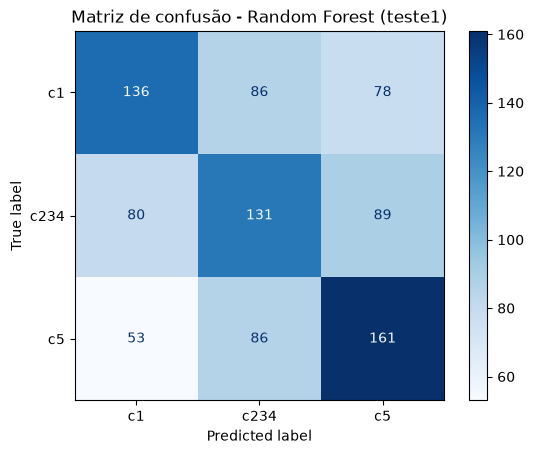

In [23]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred_test1 = modelo_final.predict(Xc_test1)

acc_rf = accuracy_score(y_test1, pred_test1)
print(f"Acurácia no teste1 (Random Forest): {acc_rf:.4f}")
print(f"Acurácia no teste1 (EP1 - Reg. Log. + TF-IDF): 0.4967\n")
print(classification_report(y_test1, pred_test1, digits=4))

ConfusionMatrixDisplay.from_predictions(y_test1, pred_test1, cmap="Blues")
plt.title("Matriz de confusão - Random Forest (teste1)")
plt.show()


### Teste de McNemar: EP1 x Random Forest

O teste de McNemar compara dois classificadores **nas mesmas instâncias**. Ele olha só para os casos em que os modelos discordam:

- `b` = instâncias que o EP1 acertou e a Random Forest errou;
- `c` = instâncias que a Random Forest acertou e o EP1 errou.

Se os dois modelos fossem equivalentes, esperaríamos `b ≈ c`. Um p-valor < 0,05 indica diferença estatisticamente significativa.

As predições do EP1 no teste1 estão em `data/test1_rotulado_ep1.xlsx`.


In [24]:
from scipy.stats import binomtest, chi2

pred_ep1 = pd.read_excel("data/test1_rotulado_ep1.xlsx")["clarity"].values
assert len(pred_ep1) == len(y_test1)
print(f"Acurácia do EP1 recalculada: {accuracy_score(y_test1, pred_ep1):.4f}")

acerto_ep1 = pred_ep1 == y_test1.values
acerto_rf = pred_test1 == y_test1.values

tabela = pd.DataFrame(
    [[np.sum(acerto_ep1 & acerto_rf), np.sum(acerto_ep1 & ~acerto_rf)],
     [np.sum(~acerto_ep1 & acerto_rf), np.sum(~acerto_ep1 & ~acerto_rf)]],
    index=["EP1 acertou", "EP1 errou"], columns=["RF acertou", "RF errou"],
)
display(tabela)

b = np.sum(acerto_ep1 & ~acerto_rf)
c = np.sum(~acerto_ep1 & acerto_rf)
estatistica = (abs(b - c) - 1) ** 2 / (b + c)          # com correção de continuidade
p_chi2 = chi2.sf(estatistica, df=1)
p_exato = binomtest(min(b, c), b + c, 0.5).pvalue        # versão exata (binomial)

print(f"b (só EP1 acertou) = {b} | c (só RF acertou) = {c}")
print(f"McNemar (qui-quadrado): estatística = {estatistica:.3f}, p = {p_chi2:.4f}")
print(f"McNemar (exato):        p = {p_exato:.4f}")


Acurácia do EP1 recalculada: 0.4967


,RF acertou,RF errou
EP1 acertou,322,125
EP1 errou,106,347


b (só EP1 acertou) = 125 | c (só RF acertou) = 106
McNemar (qui-quadrado): estatística = 1.403, p = 0.2363
McNemar (exato):        p = 0.2362


## Importância das características

Uma das motivações para usar a Random Forest é poder analisar **quais propriedades linguísticas pesam mais** na classificação. Usamos duas medidas complementares:

1. **Importância por impureza (MDI):** quanto cada característica reduz, em média, a impureza (Gini) nas divisões das árvores. É calculada no treino e é rápida, mas tende a favorecer características contínuas com muitos valores distintos.
2. **Importância por permutação (no teste1):** embaralhamos uma coluna por vez e medimos quanto a acurácia cai. Mede o impacto real no desempenho em dados não vistos. A coluna `__texto` é embaralhada como um bloco, o que mede o efeito conjunto das 9 características do léxico de clareza.

As características também foram agrupadas por tipo, para facilitar a leitura.


Importância total por grupo (MDI):


grupo
Léxico de clareza                     0.468
Linguísticas (estilo/legibilidade)    0.381
Grupos lexicais                       0.151
Name: importancia, dtype: float64

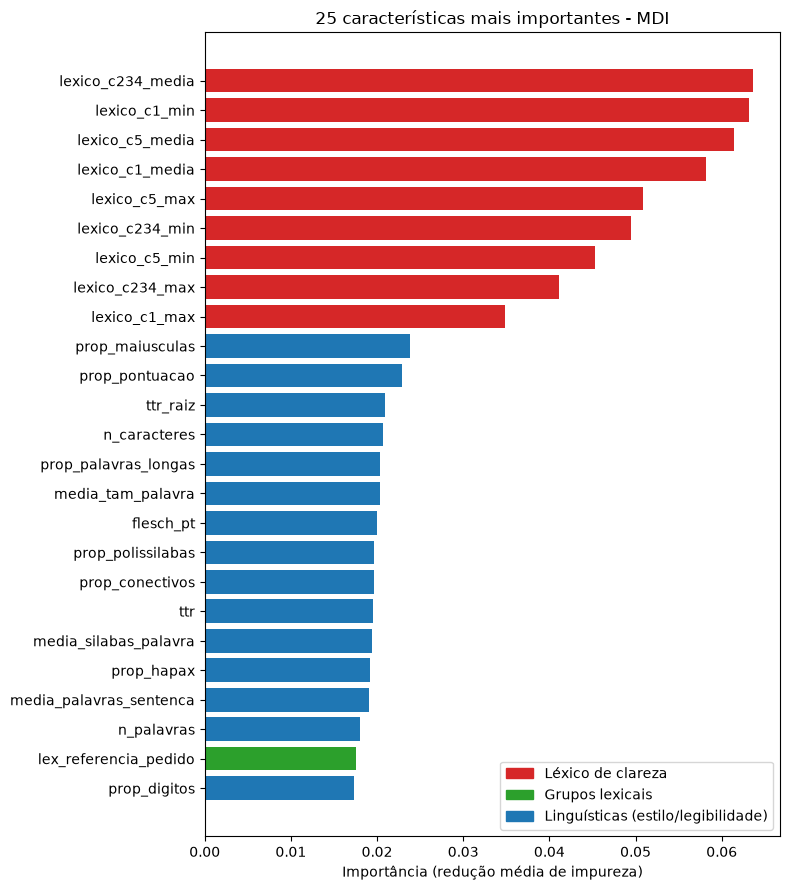

In [26]:
rf_final = modelo_final.named_steps["rf"]
nomes = modelo_final.named_steps["lexico"].get_feature_names_out()

def grupo_da_feature(nome):
    if nome.startswith("lexico_"):
        return "Léxico de clareza"
    if nome.startswith("lex_"):
        return "Grupos lexicais"
    return "Linguísticas (estilo/legibilidade)"

imp_mdi = (pd.DataFrame({"feature": nomes, "importancia": rf_final.feature_importances_})
           .assign(grupo=lambda d: d["feature"].map(grupo_da_feature))
           .sort_values("importancia", ascending=False)
           .reset_index(drop=True))

print("Importância total por grupo (MDI):")
display(imp_mdi.groupby("grupo")["importancia"].sum().sort_values(ascending=False).round(3))

cores = {"Léxico de clareza": "tab:red", "Grupos lexicais": "tab:green",
         "Linguísticas (estilo/legibilidade)": "tab:blue"}
top = imp_mdi.head(25).iloc[::-1]
plt.figure(figsize=(8, 9))
plt.barh(top["feature"], top["importancia"], color=top["grupo"].map(cores))
plt.xlabel("Importância (redução média de impureza)")
plt.title("25 características mais importantes - MDI")
plt.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cores.values()],
           labels=list(cores.keys()), loc="lower right")
plt.tight_layout()
plt.show()


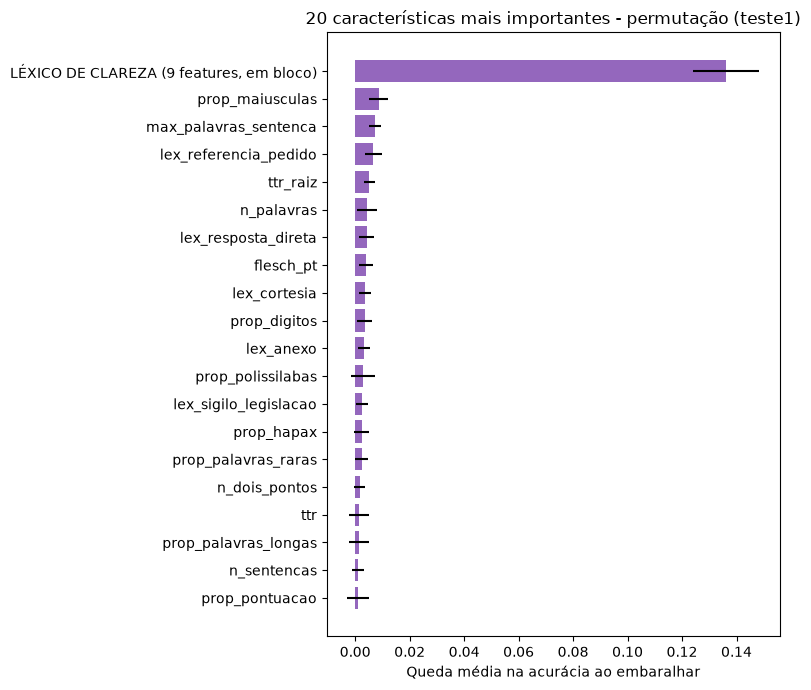

,feature,queda_media_acuracia,desvio
0,"LÉXICO DE CLAREZA (9 features, em bloco)",0.1362,0.0122
1,prop_maiusculas,0.0086,0.0035
2,max_palavras_sentenca,0.0071,0.0022
3,lex_referencia_pedido,0.0067,0.0030
4,ttr_raiz,0.0052,0.0019
5,n_palavras,0.0043,0.0037
6,lex_resposta_direta,0.0042,0.0027
7,flesch_pt,0.0040,0.0027
8,lex_cortesia,0.0036,0.0022
9,prop_digitos,0.0036,0.0028


In [25]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(modelo_final, Xc_test1, y_test1, scoring="accuracy",
                              n_repeats=10, random_state=123, n_jobs=1)

imp_perm = (pd.DataFrame({"feature": Xc_test1.columns,
                          "queda_media_acuracia": perm.importances_mean,
                          "desvio": perm.importances_std})
            .replace({"feature": {"__texto": "LÉXICO DE CLAREZA (9 features, em bloco)"}})
            .sort_values("queda_media_acuracia", ascending=False)
            .reset_index(drop=True))

top = imp_perm.head(20).iloc[::-1]
plt.figure(figsize=(8, 7))
plt.barh(top["feature"], top["queda_media_acuracia"], xerr=top["desvio"], color="tab:purple")
plt.xlabel("Queda média na acurácia ao embaralhar")
plt.title("20 características mais importantes - permutação (teste1)")
plt.tight_layout()
plt.show()

imp_perm.round(4)


### Como as características mais importantes variam entre as classes

Média, por classe (no treino), das 10 características com maior importância MDI. Ajuda a interpretar a **direção** do efeito, por exemplo se respostas mais claras (c5) são mais curtas ou têm mais menções a anexos.


In [27]:
entrada_treino = modelo_final.named_steps["lexico"].transform(Xc_train)
df_imp = pd.DataFrame(entrada_treino, columns=nomes).assign(clarity=y_train.values)
top10 = imp_mdi["feature"].head(10).tolist()
df_imp.groupby("clarity")[top10].mean().T.round(4)


clarity,c1,c234,c5
lexico_c234_media,0.1256,0.1498,0.1201
lexico_c1_min,-0.5727,-0.8960,-0.9831
lexico_c5_media,-0.2540,-0.2266,-0.1641
lexico_c1_media,0.1139,0.0609,0.0272
lexico_c5_max,0.4592,0.5408,0.7727
lexico_c234_min,-0.5185,-0.3445,-0.5476
lexico_c5_min,-1.0868,-1.0296,-0.7630
lexico_c234_max,0.5604,0.7336,0.5599
lexico_c1_max,0.8456,0.6979,0.6208
prop_maiusculas,0.0753,0.0737,0.0752
